# Heart Sync
## 30-Day Heart Failure Readmission Prediction

**Objective:** Predict whether an eligible hospital admission is followed by a readmission within 30 days.

This project builds and evaluates machine-learning models using admission-level demographic, administrative, diagnostic, laboratory, and text-derived features. The workflow includes patient-level data splitting, preprocessing, model comparison, Optuna-based hyperparameter optimization, threshold selection, held-out evaluation, and SHAP explainability.

**Target definition:** `readmit_within_30 = 1` when `days_to_readmit < 30`; otherwise `0`. Missing `days_to_readmit` values are treated as no recorded readmission. This label definition assumes that each admission has a complete 30-day observation window. Confirm follow-up completeness before making clinical claims.

**Prediction timing:** `discharge_location` is included as a predictor. Therefore, interpret this model as a discharge-time prediction workflow, not as a model intended to predict risk at the start of admission.

> **Data and safety:** The notebook expects a prepared CSV in Google Drive. Do not upload raw MIMIC-III data, patient-level records, or identifying information to a public GitHub repository. This is an educational project, not a clinically validated decision-support system.

## 1. Environment and imports

Install the libraries used in the notebook. In Google Colab, run this cell once per fresh runtime.

In [ ]:
%pip install -q category_encoders xgboost shap

In [ ]:
import os
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.model_selection import GroupShuffleSplit, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

from category_encoders import TargetEncoder

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_recall_curve

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

## 2. Load the prepared dataset

Update `data_path` if `final_df.csv` is stored in a different Google Drive folder. The CSV is not embedded in this notebook.

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

data_path = "/content/drive/MyDrive/Provided Tables/final_df.csv"

if not os.path.exists(data_path):
    raise FileNotFoundError(
        f"Dataset not found at: {data_path}. Update data_path to the location of final_df.csv."
    )

raw_df = pd.read_csv(data_path)
print(f"Dataset shape: {raw_df.shape}")
display(raw_df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset shape: (14040, 23)


,Unnamed: 0,subject_id,hadm_id,admittime,dischtime,admission_type,discharge_location,ethnicity,cpt_cd,all_diagnosis,...,drg_type,drg_code,description,drg_severity,drg_mortality,age,next_admittime,days_to_readmit,procedure_pairs,lab_events
0,0,3,145834,2101-10-20 19:08:00,2101-10-31 13:58:00,EMERGENCY,SNF,WHITE,"['94002', '94003']","0389,78559,5849,4275,41071,4280,6826,4254,2639",...,HCFA,416.0,SEPTICEMIA AGE >17,NaN,NaN,76.0,NaN,NaN,"[(1, 9604), (2, 9962), (3, 8964), (4, 9672), (...","[(50868, '17', 'normal', 10.89), (50882, '25',..."
1,1,9,150750,2149-11-09 13:06:00,2149-11-14 10:15:00,EMERGENCY,DEAD/EXPIRED,UNKNOWN/NOT SPECIFIED,['94003'],"431,5070,4280,5849,2765,4019",...,HCFA,14.0,INTRACRANIAL HEMORRHAGE & STROKE W/ INFARCTION,NaN,NaN,41.0,NaN,NaN,"[(1, 9672), (2, 9604)]","[(50819, '5', 'normal', 0.17), (50820, '7.41',..."
2,2,21,109451,2134-09-11 12:17:00,2134-09-24 16:15:00,EMERGENCY,REHAB/DISTINCT PART HOSP,WHITE,"[99255, 99292, 99291, 99231, 90935, 99232, 909...","41071,78551,5781,5849,40391,4280,4592,5070,427...",...,APR,1744.0,Percutaneous Cardiovascular Procedures w/ AMI,4.0,4.0,87.0,NaN,NaN,"[(1, 66), (2, 3761), (3, 3950), (4, 3606), (5,...","[(51274, '15.5', 'abnormal', 9.6), (51275, '49..."
3,3,26,197661,2126-05-06 15:16:00,2126-05-13 15:00:00,EMERGENCY,HOME,UNKNOWN/NOT SPECIFIED,"[99223, 99231]","99604,4271,4280,42731,41401,412,5939,2720,60000",...,HCFA,515.0,CARDIAC DEFIBRILLATOR IMPLANT WITHOUT CARDIAC ...,NaN,NaN,72.0,NaN,NaN,"[(1, 3794), (2, 8959)]","[(51237, '1.3', 'normal', 4.44), (51248, '32.2..."
4,4,30,104557,2172-10-14 14:17:00,2172-10-19 14:37:00,URGENT,HOME HEALTH CARE,UNKNOWN/NOT SPECIFIED,NaN,"99674,4160,4111,4281,4271,41401,4019,2720,5939",...,HCFA,468.0,EXTENSIVE OPERATING ROOM PROCEDURE UNRELATED T...,NaN,NaN,NaN,NaN,NaN,"[(1, 8601), (2, 3723), (3, 8855), (4, 9227)]","[(50800, 'ART', 'normal', 4.94), (50802, '-9',..."


## 3. Define the modelling cohort and target

The modelling table retains both admissions with a recorded readmission interval and admissions without one. Negative intervals are excluded as invalid. `subject_id` is retained only for patient-level splitting and is not used as a model feature.

In [ ]:
model_columns = [
    "admission_type", "discharge_location", "ethnicity", "cpt_cd",
    "all_diagnosis", "gender", "drg_type", "drg_code", "description",
    "drg_severity", "drg_mortality", "age", "procedure_pairs",
    "lab_events", "days_to_readmit"
]
required_columns = model_columns + ["subject_id"]

missing_columns = sorted(set(required_columns) - set(raw_df.columns))
if missing_columns:
    raise KeyError(f"Required columns missing from dataset: {missing_columns}")

df = raw_df[required_columns].copy()

# Remove invalid negative intervals while retaining missing intervals.
df = df[df["days_to_readmit"].isna() | (df["days_to_readmit"] >= 0)].copy()

# Preserve the original notebook's strict '< 30 days' threshold.
df["readmit_within_30"] = (
    df["days_to_readmit"].notna() & (df["days_to_readmit"] < 30)
).astype("int8")

print(f"Rows after invalid-interval filtering: {len(df):,}")
print("\nTarget distribution:")
display(df["readmit_within_30"].value_counts().rename_axis("readmit_within_30").to_frame("count"))
display((df["readmit_within_30"].value_counts(normalize=True) * 100)
        .rename("percentage").to_frame())

Rows after invalid-interval filtering: 13,977

Target distribution:


,count
readmit_within_30,
0,12334
1,1643


,percentage
readmit_within_30,
0,88.244974
1,11.755026


## 4. Missing-value handling and text preparation

Rows missing the core DRG description fields or laboratory-event text are excluded, consistent with the original preparation workflow. Remaining imputations are learned inside the preprocessing pipeline from the training data only.

In [ ]:
rows_before = len(df)
df = df.dropna(subset=["drg_type", "drg_code", "description", "lab_events"]).copy()
print(f"Rows removed for missing core fields: {rows_before - len(df):,}")

# Normalize text consistently before TF-IDF vectorization.
punctuation_to_remove = string.punctuation.replace(",", "")

def clean_text(value):
    value = str(value).lower()
    return value.translate(str.maketrans("", "", punctuation_to_remove))

text_columns = ["cpt_cd", "all_diagnosis", "description", "procedure_pairs", "lab_events"]
for column in text_columns:
    df[column] = df[column].fillna("").map(clean_text)

print(f"Rows available for modelling: {len(df):,}")
print("\nMissing values in selected fields:")
display(df[model_columns].isna().sum().to_frame("missing_count"))

Rows removed for missing core fields: 123
Rows available for modelling: 13,854

Missing values in selected fields:


,missing_count
admission_type,0
discharge_location,0
ethnicity,0
cpt_cd,0
all_diagnosis,0
gender,0
drg_type,0
drg_code,0
description,0
drg_severity,4152


## 5. Patient-level train-test split

A grouped split keeps admissions from the same `subject_id` together, reducing patient overlap between training and test data. The test set is held out from model selection and threshold optimization.

In [ ]:
X = df.drop(columns=["days_to_readmit", "readmit_within_30", "subject_id"])
y = df["readmit_within_30"]
groups = df["subject_id"]

group_split = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=RANDOM_STATE
)
train_idx, test_idx = next(group_split.split(X, y, groups=groups))

X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()

print(f"Training admissions: {len(X_train):,}")
print(f"Test admissions: {len(X_test):,}")
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())
print("\nTest target distribution:")
display(y_test.value_counts(normalize=True).rename("proportion").to_frame())

Training admissions: 11,093
Test admissions: 2,761

Training target distribution:


,proportion
readmit_within_30,
0,0.880645
1,0.119355



Test target distribution:


,proportion
readmit_within_30,
0,0.88736
1,0.11264


## 6. Feature preprocessing

- Categorical variables are one-hot encoded or target encoded.
- Clinical text fields are transformed using TF-IDF.
- Age is median-imputed and standardized.
- DRG severity and mortality are imputed and one-hot encoded.

The custom TF-IDF transformer is compatible with scikit-learn pipelines.

In [ ]:
class TfidfColumnTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, stop_words="english", max_features=None, ngram_range=(1, 1)):
        self.stop_words = stop_words
        self.max_features = max_features
        self.ngram_range = ngram_range

    def fit(self, X, y=None):
        values = pd.Series(np.asarray(X).ravel()).fillna("").astype(str)
        self.vectorizer_ = TfidfVectorizer(
            stop_words=self.stop_words,
            max_features=self.max_features,
            ngram_range=self.ngram_range,
        )
        self.vectorizer_.fit(values)
        return self

    def transform(self, X):
        values = pd.Series(np.asarray(X).ravel()).fillna("").astype(str)
        return self.vectorizer_.transform(values)


age_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

drg_category_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("admission_type", OneHotEncoder(handle_unknown="ignore"), ["admission_type"]),
        ("discharge_location", TargetEncoder(), ["discharge_location"]),
        ("ethnicity", TargetEncoder(), ["ethnicity"]),
        ("cpt_cd", TfidfColumnTransformer(), ["cpt_cd"]),
        ("all_diagnosis", TfidfColumnTransformer(), ["all_diagnosis"]),
        ("gender", OneHotEncoder(handle_unknown="ignore"), ["gender"]),
        ("drg_type", OneHotEncoder(handle_unknown="ignore"), ["drg_type"]),
        ("drg_code", TfidfColumnTransformer(), ["drg_code"]),
        ("description", TfidfColumnTransformer(), ["description"]),
        ("drg_severity", drg_category_pipeline, ["drg_severity"]),
        ("drg_mortality", drg_category_pipeline, ["drg_mortality"]),
        ("age", age_pipeline, ["age"]),
        ("procedure_pairs", TfidfColumnTransformer(), ["procedure_pairs"]),
        ("lab_events", TfidfColumnTransformer(), ["lab_events"]),
    ],
    remainder="drop",
)

print("Preprocessing pipeline configured.")

Preprocessing pipeline configured.


## 7. Model development and validation

A patient-level validation split is created from the training partition. Logistic Regression variants, Random Forest, and XGBoost configurations are compared using validation data. The held-out test set is not used for selecting a model or threshold.

In [ ]:
# Create patient-level validation split

train_groups = groups.iloc[train_idx]

inner_split = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE
)

fit_idx, val_idx = next(
    inner_split.split(X_train, y_train, groups=train_groups)
)

X_fit = X_train.iloc[fit_idx]
X_val = X_train.iloc[val_idx]

y_fit = y_train.iloc[fit_idx]
y_val = y_train.iloc[val_idx]


candidate_specs = {
    "Logistic Regression - No PCA, Balanced": {
        "pca": False,
        "class_weight": "balanced"
    },
    "Logistic Regression - No PCA, Unweighted": {
        "pca": False,
        "class_weight": None
    },
    "Logistic Regression - PCA, Balanced": {
        "pca": True,
        "class_weight": "balanced"
    }
}

candidate_models = {}
validation_rows = []

for name, spec in candidate_specs.items():

    steps = [("preprocessor", clone(preprocessor))]

    if spec["pca"]:
        steps.extend([
            ("to_dense", FunctionTransformer(
                lambda x: x.toarray() if hasattr(x, "toarray") else x,
                accept_sparse=True
            )),
            ("pca", PCA(
                n_components=100,
                random_state=RANDOM_STATE
            ))
        ])

    steps.append((
        "classifier",
        LogisticRegression(
            C=0.6194990164033582,
            penalty="l2",
            solver="liblinear",
            class_weight=spec["class_weight"],
            max_iter=1000,
            random_state=RANDOM_STATE
        )
    ))

    model = Pipeline(steps)

    model.fit(X_fit, y_fit)

    val_prob = model.predict_proba(X_val)[:, 1]
    val_pred = (val_prob >= 0.5).astype(int)

    candidate_models[name] = model

    validation_rows.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_val, val_prob),
        "Average Precision": average_precision_score(y_val, val_prob),
        "F1-score": f1_score(y_val, val_pred, zero_division=0),
        "Precision": precision_score(y_val, val_pred, zero_division=0),
        "Recall": recall_score(y_val, val_pred, zero_division=0)
    })


# Majority-class baseline

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_fit, y_fit)

dummy_prob = dummy.predict_proba(X_val)[:, 1]

validation_rows.append({
    "Model": "Majority-class baseline",
    "ROC-AUC": np.nan,
    "Average Precision": average_precision_score(y_val, dummy_prob),
    "F1-score": 0,
    "Precision": 0,
    "Recall": 0
})


validation_comparison = pd.DataFrame(validation_rows)

validation_comparison = validation_comparison.sort_values(
    "Average Precision",
    ascending=False
)

display(validation_comparison.round(4))

,Model,ROC-AUC,Average Precision,F1-score,Precision,Recall
1,"Logistic Regression - No PCA, Unweighted",0.6967,0.2405,0.0803,0.4783,0.0438
0,"Logistic Regression - No PCA, Balanced",0.6909,0.2319,0.2591,0.1959,0.3825
2,"Logistic Regression - PCA, Balanced",0.6647,0.1940,0.2646,0.1693,0.6056
3,Majority-class baseline,NaN,0.1136,0.0000,0.0000,0.0000


### 7.1 Add baseline model candidates

In [ ]:
experiment_models = {
    "Logistic Regression": candidate_models[
        "Logistic Regression - No PCA, Unweighted"
    ]
}

print("Baseline Logistic Regression added.")

Baseline Logistic Regression added.


In [ ]:
rf_unweighted = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=4,
        max_features="sqrt",
        class_weight=None,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_balanced = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_split=10,
        min_samples_leaf=4,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_unweighted.fit(X_fit, y_fit)
rf_balanced.fit(X_fit, y_fit)

experiment_models["Random Forest - Unweighted"] = rf_unweighted
experiment_models["Random Forest - Balanced"] = rf_balanced

print("Random Forest experiments completed.")

Random Forest experiments completed.


In [ ]:
positive_count = int(y_fit.sum())
negative_count = len(y_fit) - positive_count

scale_weight = negative_count / max(positive_count, 1)

xgb_unweighted = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        scale_pos_weight=1,
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_balanced = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        scale_pos_weight=scale_weight,
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_unweighted.fit(X_fit, y_fit)
xgb_balanced.fit(X_fit, y_fit)

experiment_models["XGBoost - Unweighted"] = xgb_unweighted
experiment_models["XGBoost - Balanced"] = xgb_balanced

print("XGBoost experiments completed.")
print("Scale positive weight:", round(scale_weight, 3))

XGBoost experiments completed.
Scale positive weight: 7.28


### 7.2 Validation threshold comparison

For each candidate, the classification threshold is selected by maximizing validation F1-score. This threshold selection uses validation predictions only.

In [ ]:
experiment_results = []
experiment_thresholds = {}

for name, model in experiment_models.items():

    val_prob = model.predict_proba(X_val)[:, 1]

    precision_values, recall_values, thresholds = (
        precision_recall_curve(y_val, val_prob)
    )

    f1_values = (
        2 * precision_values[:-1] * recall_values[:-1]
        / (
            precision_values[:-1]
            + recall_values[:-1]
            + 1e-12
        )
    )

    best_idx = np.argmax(f1_values)
    threshold = float(thresholds[best_idx])

    val_pred = (val_prob >= threshold).astype(int)

    experiment_thresholds[name] = threshold

    experiment_results.append({
        "Model": name,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(
            y_val, val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, val_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, val_prob),
        "Average Precision": average_precision_score(
            y_val, val_prob
        )
    })

experiment_comparison = pd.DataFrame(experiment_results)

experiment_comparison = experiment_comparison.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(experiment_comparison.round(4))

,Model,Threshold,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,XGBoost - Balanced,0.3929,0.7198,0.2318,0.6335,0.3394,0.7432,0.2729
1,XGBoost - Unweighted,0.1096,0.6840,0.2196,0.6972,0.3340,0.7453,0.2747
2,Logistic Regression,0.0975,0.6175,0.1874,0.7092,0.2964,0.6967,0.2405
3,Random Forest - Unweighted,0.1412,0.7438,0.2131,0.4661,0.2925,0.6760,0.2070
4,Random Forest - Balanced,0.4092,0.7094,0.1960,0.5020,0.2819,0.6643,0.1798


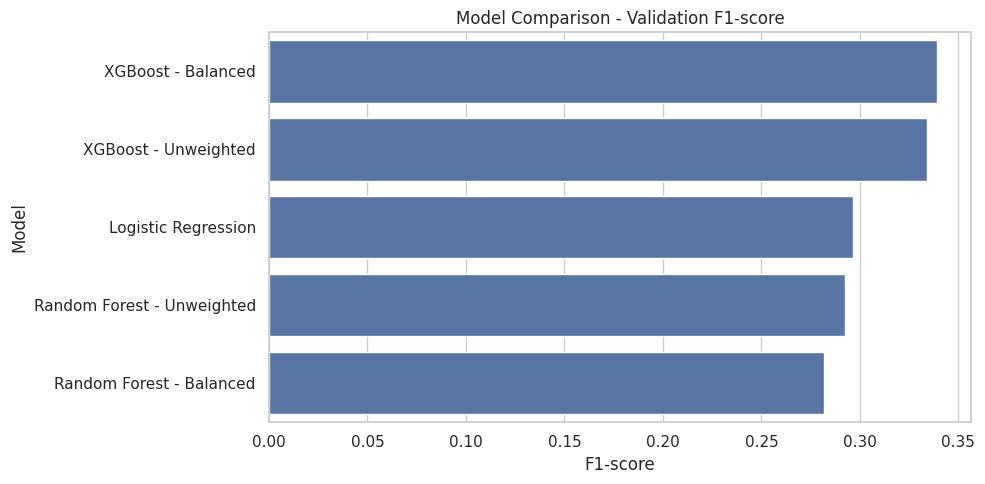

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=experiment_comparison,
    x="F1-score",
    y="Model"
)

plt.title("Model Comparison - Validation F1-score")
plt.xlabel("F1-score")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

In [ ]:
best_model_name = experiment_comparison.loc[0, "Model"]

best_threshold = experiment_thresholds[best_model_name]

best_model = experiment_models[best_model_name]

print("Best model:", best_model_name)
print("Selected threshold:", round(best_threshold, 4))

print(
    "Validation F1-score:",
    round(experiment_comparison.loc[0, "F1-score"], 4)
)

Best model: XGBoost - Balanced
Selected threshold: 0.3929
Validation F1-score: 0.3394


## 8. Optuna hyperparameter optimization

A 20-trial Optuna search using grouped cross-validation was completed during development. Its best cross-validation Average Precision was approximately **0.277**.

To keep this portfolio notebook practical to rerun, the best parameters from that completed search are recorded below and reused directly. **The expensive Optuna search is not run again by this notebook.** The optional search procedure can be added separately if a fresh tuning study is required.

In [ ]:
# Best hyperparameters retained from the completed Optuna study.
best_xgb_params = {
    "n_estimators": 400,
    "max_depth": 3,
    "learning_rate": 0.012382296822076453,
    "subsample": 0.950118899790334,
    "colsample_bytree": 0.6112886787628036,
    "min_child_weight": 10,
    "reg_lambda": 0.7401894384799756,
    "scale_pos_weight": 2.072904347283351,
}

print("Using the previously optimized Optuna parameters:")
print(best_xgb_params)

Using the previously optimized Optuna parameters:
{'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.012382296822076453, 'subsample': 0.950118899790334, 'colsample_bytree': 0.6112886787628036, 'min_child_weight': 10, 'reg_lambda': 0.7401894384799756, 'scale_pos_weight': 2.072904347283351}


### 8.1 Train the tuned XGBoost model

The tuned pipeline is fitted on the fitting portion of the training data (`X_fit`, `y_fit`). The validation partition is retained for threshold selection and model comparison.

In [ ]:
tuned_xgb = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        **best_xgb_params,
        eval_metric="logloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

tuned_xgb.fit(X_fit, y_fit)
print("Optuna-tuned XGBoost model trained successfully.")

Optuna-tuned XGBoost model trained successfully.


### 8.2 Select the classification threshold on validation data

The threshold is selected by maximizing validation F1-score, balancing precision and recall. The test set is not used in this step.

In [ ]:
tuned_val_prob = tuned_xgb.predict_proba(X_val)[:, 1]

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_val, tuned_val_prob)
)

f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (
        precision_values[:-1]
        + recall_values[:-1]
        + 1e-12
    )
)

best_tuned_threshold = float(
    thresholds[np.argmax(f1_values)]
)

print("Optimized threshold:", round(best_tuned_threshold, 4))
print("Validation F1:", round(np.max(f1_values), 4))

Optimized threshold: 0.2728
Validation F1: 0.3409


### 8.3 Compare the original and tuned XGBoost models

In [ ]:
# Existing XGBoost Balanced model
old_val_prob = best_model.predict_proba(X_val)[:, 1]

old_val_pred = (
    old_val_prob >= best_threshold
).astype(int)

# Tuned XGBoost
tuned_val_pred = (
    tuned_val_prob >= best_tuned_threshold
).astype(int)

comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost Balanced",
        "Precision": precision_score(
            y_val, old_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, old_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, old_val_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, old_val_prob),
        "Average Precision": average_precision_score(
            y_val, old_val_prob
        )
    },
    {
        "Model": "Optuna Tuned XGBoost",
        "Precision": precision_score(
            y_val, tuned_val_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, tuned_val_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, tuned_val_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_val, tuned_val_prob),
        "Average Precision": average_precision_score(
            y_val, tuned_val_prob
        )
    }
])

display(comparison.round(4))

,Model,Precision,Recall,F1-score,ROC-AUC,Average Precision
0,Original XGBoost Balanced,0.2318,0.6335,0.3394,0.7432,0.2729
1,Optuna Tuned XGBoost,0.2432,0.5697,0.3409,0.7590,0.2832


## 9. Final evaluation on the held-out test set

The tuned XGBoost pipeline is evaluated once on the untouched test set using the threshold selected from validation data. The reported metrics below are the saved results from the completed experiment.

In [ ]:
# Final evaluation on untouched test dataset

y_test_prob = tuned_xgb.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_prob >= best_tuned_threshold
).astype(int)

print("Final test predictions generated.")

Final test predictions generated.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report
)

final_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_test_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_test_prob),
    "Average Precision": average_precision_score(y_test, y_test_prob)
}

final_results = pd.DataFrame(
    list(final_metrics.items()),
    columns=["Metric", "Score"]
)

display(final_results.round(4))

print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_test_pred,
    zero_division=0
))

,Metric,Score
0,Accuracy,0.7530
1,Precision,0.2448
2,Recall,0.5723
3,F1-score,0.3430
4,ROC-AUC,0.7551
5,Average Precision,0.2677



Classification Report:

              precision    recall  f1-score   support

           0       0.93      0.78      0.85      2450
           1       0.24      0.57      0.34       311

    accuracy                           0.75      2761
   macro avg       0.59      0.67      0.60      2761
weighted avg       0.86      0.75      0.79      2761



### 9.1 Confusion matrix

Confusion Matrix:
[[1901  549]
 [ 133  178]]


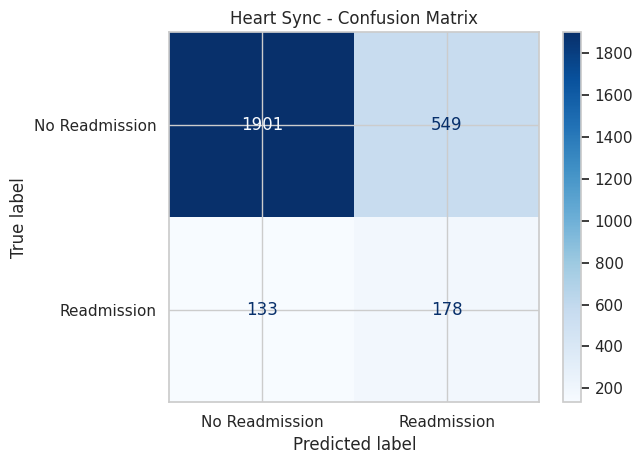

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Readmission", "Readmission"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Heart Sync - Confusion Matrix")
plt.tight_layout()
plt.show()

### 9.2 ROC curve

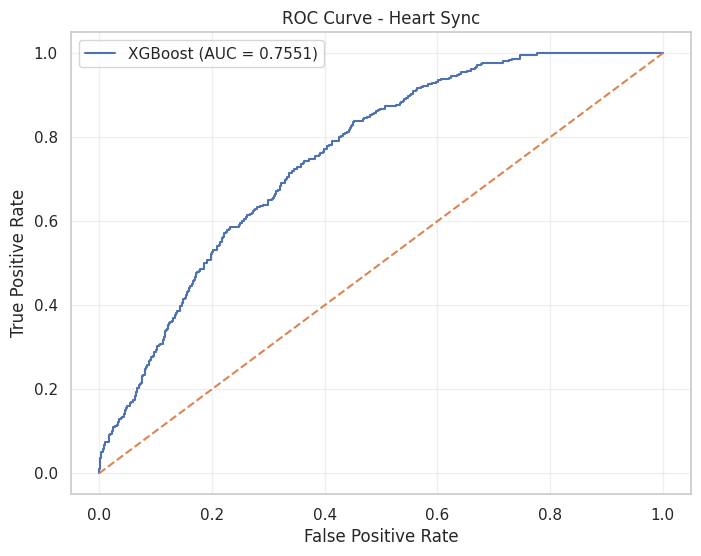

In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds_roc = roc_curve(
    y_test,
    y_test_prob
)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {roc_auc:.4f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Heart Sync")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 9.3 Precision-recall curve

The precision-recall curve is particularly informative because readmission is the minority class.

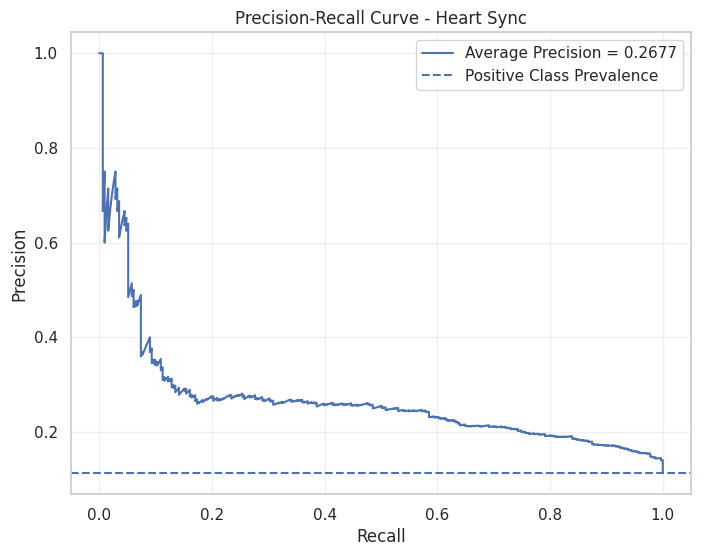

In [ ]:
from sklearn.metrics import precision_recall_curve

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(y_test, y_test_prob)
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Average Precision = {average_precision_score(y_test, y_test_prob):.4f}"
)

plt.axhline(
    y=np.mean(y_test),
    linestyle="--",
    label="Positive Class Prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Heart Sync")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 9.4 Save the trained model and configuration

This saves the fitted pipeline and selected threshold in the current Colab runtime. Download these artifacts separately if you need them locally. Do not upload restricted patient data.

In [ ]:
import joblib
import json

joblib.dump(tuned_xgb, "heart_sync_optuna_xgboost.pkl")

model_config = {
    "model": "Optuna Tuned XGBoost",
    "target": "readmit_within_30",
    "threshold": float(best_tuned_threshold),
    "best_cv_average_precision": 0.277,
    "validation_f1": 0.3409,
    "validation_roc_auc": 0.7590,
    "validation_average_precision": 0.2832,
    "test_metrics": {
        "accuracy": 0.7530,
        "precision": 0.2448,
        "recall": 0.5723,
        "f1_score": 0.3430,
        "roc_auc": 0.7551,
        "average_precision": 0.2677
    },
    "hyperparameters": best_xgb_params
}

with open("heart_sync_optuna_config.json", "w") as f:
    json.dump(model_config, f, indent=4)

print("Tuned model and configuration saved!")

Tuned model and configuration saved!


## 10. Explainable AI with SHAP

SHAP is used to explain how the fitted XGBoost model uses input features. A sample of 100 validation admissions is used to keep the explanation workload manageable. SHAP values describe model behaviour; they do not establish clinical causation.

In [ ]:
import shap

print("SHAP version:", shap.__version__)

SHAP version: 0.54.1


### 10.1 Extract the fitted classifier and prepare a validation sample

In [ ]:
# Extract preprocessing and XGBoost classifier

xgb_classifier = tuned_xgb.named_steps["classifier"]

fitted_preprocessor = tuned_xgb.named_steps["preprocessor"]

print("Selected model: Optuna Tuned XGBoost")
print("Model successfully loaded from trained pipeline.")

Selected model: Optuna Tuned XGBoost
Model successfully loaded from trained pipeline.


In [ ]:
# Select a sample of validation records

X_shap_raw = X_val.sample(
    n=min(100, len(X_val)),
    random_state=RANDOM_STATE
)

# Transform using the already fitted preprocessor

X_shap_transformed = fitted_preprocessor.transform(
    X_shap_raw
)

# Convert sparse matrix to dense if necessary

if hasattr(X_shap_transformed, "toarray"):
    X_shap_transformed = X_shap_transformed.toarray()

# Extract feature names

try:
    feature_names = fitted_preprocessor.get_feature_names_out()
except Exception:
    feature_names = [
        f"Feature_{i}"
        for i in range(X_shap_transformed.shape[1])
    ]

X_shap_df = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names
)

print("SHAP sample shape:", X_shap_df.shape)

SHAP sample shape: (100, 17178)


### 10.2 Recover the transformed feature names

The preprocessing pipeline creates many TF-IDF features. This cell maps the transformed columns back to their learned names so that the SHAP plots are interpretable.

In [ ]:
# Recover actual feature names

all_feature_names = []

for name, transformer, columns in fitted_preprocessor.transformers_:

    if hasattr(transformer, "vectorizer_"):
        names = transformer.vectorizer_.get_feature_names_out()
        names = [f"{name}__{x}" for x in names]

    else:
        try:
            names = transformer.get_feature_names_out(columns)
        except:
            try:
                names = transformer.get_feature_names_out()
            except:
                output_slice = fitted_preprocessor.output_indices_[name]
                count = output_slice.stop - output_slice.start
                names = [f"{name}__feature_{i}" for i in range(count)]

        names = list(names)

    all_feature_names.extend(names)

print("Recovered names:", len(all_feature_names))
print("Actual features:", X_shap_transformed.shape[1])

print("\nFirst 30 feature names:")
print(all_feature_names[:30])

Recovered names: 17178
Actual features: 17178

First 30 feature names:
['admission_type_ELECTIVE', 'admission_type_EMERGENCY', 'admission_type_NEWBORN', 'admission_type_URGENT', 'discharge_location', 'ethnicity', 'cpt_cd__0050t', 'cpt_cd__0078t', 'cpt_cd__0079t', 'cpt_cd__0080t', 'cpt_cd__0081t', 'cpt_cd__01996', 'cpt_cd__0256t', 'cpt_cd__0257t', 'cpt_cd__0258t', 'cpt_cd__10060', 'cpt_cd__10061', 'cpt_cd__10120', 'cpt_cd__10121', 'cpt_cd__11004', 'cpt_cd__11006', 'cpt_cd__11008', 'cpt_cd__11012', 'cpt_cd__11040', 'cpt_cd__11042', 'cpt_cd__11043', 'cpt_cd__11044', 'cpt_cd__11045', 'cpt_cd__11046', 'cpt_cd__11403']


In [ ]:
# Update SHAP dataframe with recovered feature names

X_shap_df = pd.DataFrame(
    X_shap_transformed,
    columns=all_feature_names
)

print("Updated SHAP dataframe:", X_shap_df.shape)
print("\nTop feature names:")
print(X_shap_df.columns[:20].tolist())

Updated SHAP dataframe: (100, 17178)

Top feature names:
['admission_type_ELECTIVE', 'admission_type_EMERGENCY', 'admission_type_NEWBORN', 'admission_type_URGENT', 'discharge_location', 'ethnicity', 'cpt_cd__0050t', 'cpt_cd__0078t', 'cpt_cd__0079t', 'cpt_cd__0080t', 'cpt_cd__0081t', 'cpt_cd__01996', 'cpt_cd__0256t', 'cpt_cd__0257t', 'cpt_cd__0258t', 'cpt_cd__10060', 'cpt_cd__10061', 'cpt_cd__10120', 'cpt_cd__10121', 'cpt_cd__11004']


### 10.3 Calculate SHAP values

In [ ]:
# Create TreeExplainer

explainer = shap.TreeExplainer(xgb_classifier)

# Calculate SHAP values

shap_values = explainer.shap_values(X_shap_df)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


### 10.4 SHAP summary plot

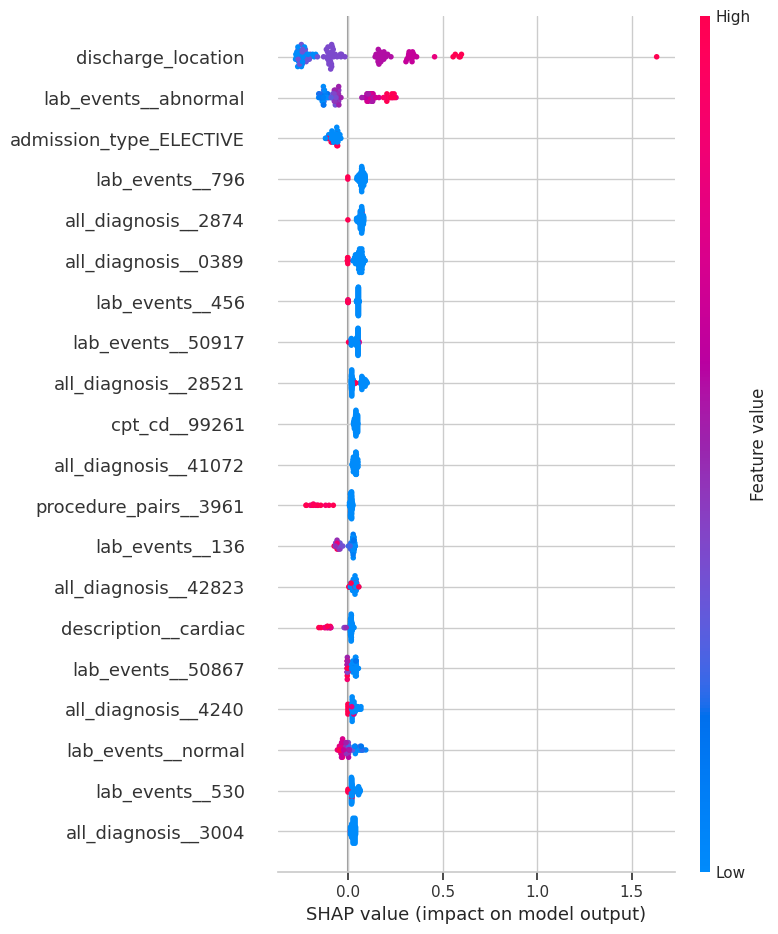

In [ ]:
shap.summary_plot(
    shap_values,
    X_shap_df,
    max_display=20
)

### 10.5 Global SHAP feature importance

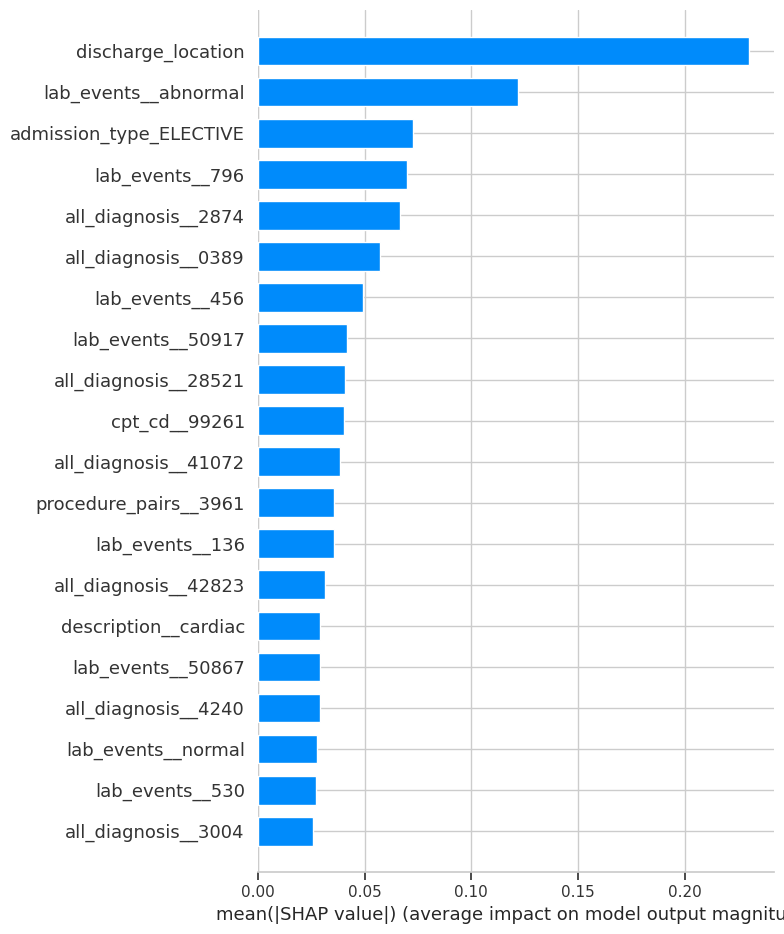

In [ ]:
shap.summary_plot(
    shap_values,
    X_shap_df,
    plot_type="bar",
    max_display=20
)

### 10.6 Individual prediction explanation

In [ ]:
# Select one validation patient

patient_index = 0

patient_data = X_shap_df.iloc[[patient_index]]

patient_shap_values = (
    shap_values[patient_index]
    if isinstance(shap_values, np.ndarray)
    else shap_values[patient_index]
)

# Get model prediction

patient_probability = tuned_xgb.predict_proba(
    X_shap_raw.iloc[[patient_index]]
)[0, 1]

patient_prediction = int(
    patient_probability >= best_tuned_threshold
)

print("Predicted readmission probability:",
      round(patient_probability, 4))

print("Classification threshold:",
      round(best_tuned_threshold, 4))

print("Predicted class:",
      "Readmission within 30 days"
      if patient_prediction == 1
      else "No readmission within 30 days")

Predicted readmission probability: 0.0126
Classification threshold: 0.2728
Predicted class: No readmission within 30 days


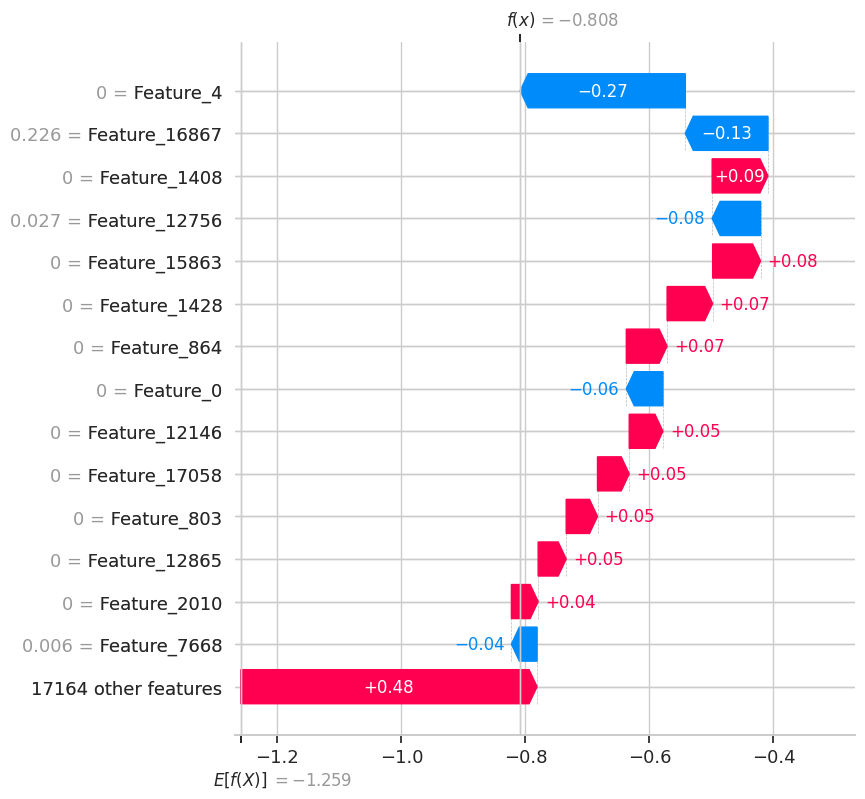

In [ ]:
base_value = explainer.expected_value

if isinstance(base_value, (list, np.ndarray)):
    base_value = np.asarray(base_value).flatten()[0]

patient_explanation = shap.Explanation(
    values=shap_values[patient_index],
    base_values=base_value,
    data=X_shap_df.iloc[patient_index].values,
    feature_names=X_shap_df.columns.tolist()
)

shap.plots.waterfall(
    patient_explanation,
    max_display=15
)

### 10.7 Top predictive features

Mean absolute SHAP values rank features by the average magnitude of their contribution across the sampled validation records. This ranking does not indicate whether a feature increases or decreases risk.

In [ ]:
# Calculate mean absolute SHAP importance

shap_importance = pd.DataFrame({
    "Feature": X_shap_df.columns,
    "Mean_SHAP_Importance": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_SHAP_Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 Important Features:")

display(shap_importance.head(20).round(5))

Top 20 Important Features:


,Feature,Mean_SHAP_Importance
0,discharge_location,0.23044
1,lab_events__abnormal,0.12211
2,admission_type_ELECTIVE,0.07276
3,lab_events__796,0.07006
4,all_diagnosis__2874,0.06660
5,all_diagnosis__0389,0.05723
6,lab_events__456,0.04923
7,lab_events__50917,0.04147
8,all_diagnosis__28521,0.04089
9,cpt_cd__99261,0.04041


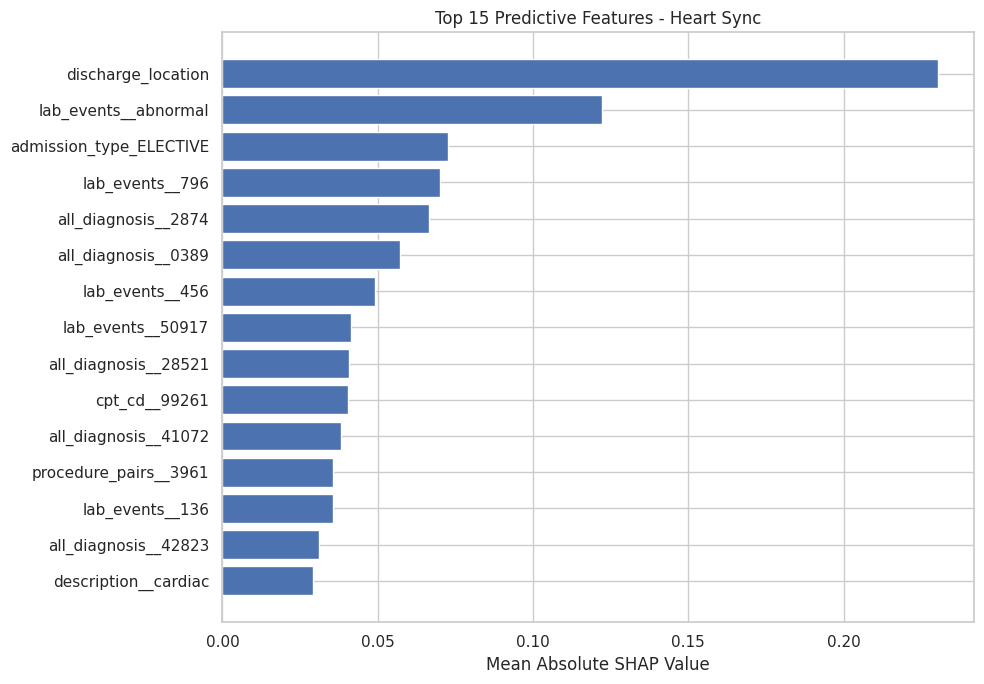

In [ ]:
top_features = shap_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Mean_SHAP_Importance"][::-1]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.title("Top 15 Predictive Features - Heart Sync")
plt.tight_layout()
plt.show()

## 11. Limitations

1. **Class imbalance:** Readmission cases are substantially less frequent than non-readmission cases.
2. **False positives:** The model flags some admissions that are not followed by a recorded readmission.
3. **False negatives:** Some actual readmissions are missed.
4. **Outcome ascertainment:** Missing `days_to_readmit` values are treated as negative labels. Complete 30-day follow-up must be confirmed.
5. **Prediction timing:** `discharge_location` is only available at discharge. The model should not be described as an admission-time predictor.
6. **Generalizability:** The model was developed on a prepared MIMIC-III-derived dataset. External validation is required before applying it to other hospitals or populations.
7. **Interpretability:** SHAP explains model associations, not causal clinical relationships.
8. **Clinical use:** This is an educational machine-learning project, not a clinically validated decision-support system.

## 12. Conclusion

Heart Sync explores the prediction of 30-day readmission using admission-level administrative, diagnostic, laboratory, demographic, and text-derived features. The workflow compares Logistic Regression, Random Forest, and XGBoost, then applies Optuna-based hyperparameter optimization and validation-based threshold selection.

The Optuna-tuned XGBoost model achieved the following results on the held-out test set:

| Metric | Test result |
|---|---:|
| Accuracy | 75.30% |
| Precision | 24.48% |
| Recall | 57.23% |
| F1-score | 34.30% |
| ROC-AUC | 75.51% |
| Average Precision | 26.77% |

SHAP was used to inspect global feature importance and an individual prediction. The results show that the model identifies a portion of readmissions, while its false-positive and false-negative predictions highlight the need for further validation and improvement.

**Reproducibility note:** This notebook reuses the best hyperparameters from the completed Optuna study rather than rerunning the 20-trial search. To reproduce the complete workflow, provide the approved source CSV at the configured Google Drive path and run the notebook from top to bottom. Model fitting and SHAP calculations will run again; the Optuna search will not.